In [2]:
!pip install pywavelets

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pywt

In [4]:
# prompt: mount google drive

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [5]:
# Load the 3D CBCT data
cbct_data = np.load("/content/drive/MyDrive/Mphil/dataset/data.npy")

# Load the 3D mask data
mask_data = np.load("/content/drive/MyDrive/Mphil/dataset/gt_alpha.npy")

# Print shape to confirm dimensions
print(f"CBCT data shape: {cbct_data.shape}")  # Should print (170, 352, 370)
print(f"Mask data shape: {mask_data.shape}")  # Should match the shape of CBCT data

CBCT data shape: (170, 352, 370)
Mask data shape: (170, 352, 370)


In [6]:
hu_min = -1000
hu_max = 3000

In [7]:
def hounsfield_to_255(hounsfield_array, hu_min=-1000, hu_max=3000):
    """
    Simple direct conversion from Hounsfield units to 0-255 intensity values.

    Parameters:
    - hounsfield_array: numpy array with Hounsfield values
    - hu_min: minimum Hounsfield value to map to 0 (default: -1000)
    - hu_max: maximum Hounsfield value to map to 255 (default: 3000)

    Returns:
    - numpy array with values scaled to 0-255 (uint8)
    """
    # Clip values to the specified range
    clipped = np.clip(hounsfield_array, hu_min, hu_max)

    # Scale to 0-255 range
    scaled = ((clipped - hu_min) / (hu_max - hu_min) * 255).astype(np.uint8)

    return scaled

In [8]:
# Convert to 0-255
converted = hounsfield_to_255(cbct_data, hu_min, hu_max)
print(converted)

[[[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 ...

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]]


## DATA VISUALISATION

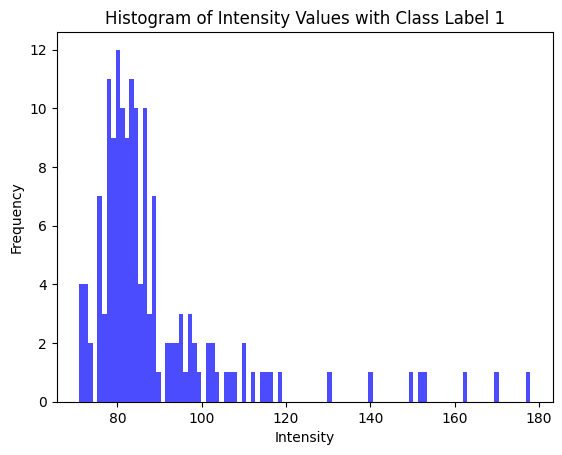

In [9]:
# Extract the midle slice from both the CBCT data and the maskalong xz plane
slice_index = 150
slice_2d = converted[:, slice_index, :]
# slice_2d = cbct_data[:, slice_index, :]
mask_2d = mask_data[:, slice_index, :]

# Extract intensity values where mask label is 1
intensity_values_class_1 = slice_2d[mask_2d == 1]

## Print the intensity values
# print(f"Intensity values with class label 1: {intensity_values_class_1}")

# print(f"Min Value: {np.min(intensity_values_class_1)}")
# print(f"Max Value: {np.max(intensity_values_class_1)}")

# Optionally, visualize these values using a histogram

plt.hist(intensity_values_class_1, bins=100, color='blue', alpha=0.7)
plt.title("Histogram of Intensity Values with Class Label 1")
plt.xlabel("Intensity")
plt.ylabel("Frequency")
plt.show()

It shows that the image is with SPARKLE NOISE. With RAYLEIGH distribution.

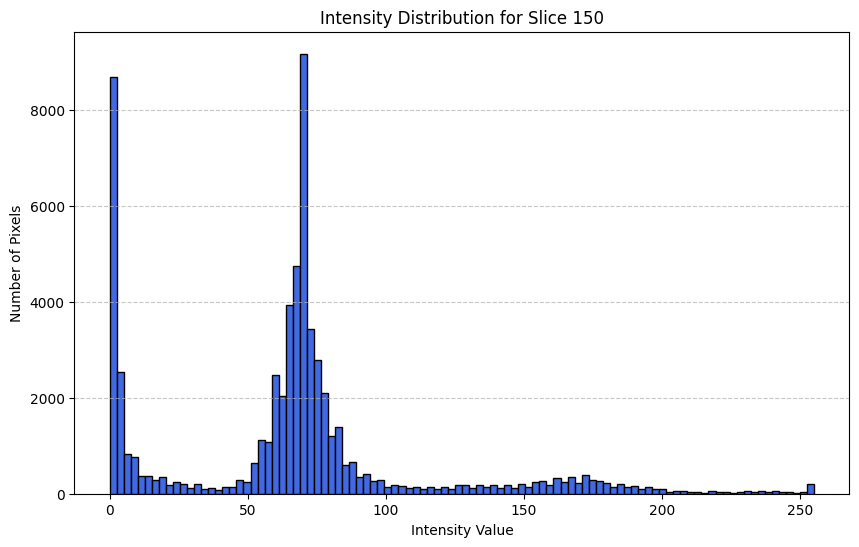

In [10]:
#visualise the slice contrast distribution
# Flatten the 2D slice into a 1D array
flattened_slice = slice_2d.flatten()

# Plot the histogram of intensity values
plt.figure(figsize=(10, 6))
plt.hist(flattened_slice, bins=100, color='royalblue', edgecolor='black')
plt.title(f"Intensity Distribution for Slice {slice_index}")
plt.xlabel("Intensity Value")
plt.ylabel("Number of Pixels")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## FILTER FUNCTIONS

### Adaptive Median Filter

In [11]:
def calculate_median(array):
    """Return the median of 1-d array"""
    sorted_array = np.sort(array) #timsort (O(nlogn))
    median = sorted_array[len(array)//2]
    return median

def level_B(z_min, z_med, z_max, z_xy, S_xy, S_max):
    """
    Level B: Check if current pixel is impulse noise
    """
    if z_min < z_xy < z_max:
        return z_xy  # Current pixel is not impulse noise, keep original
    else:
        return z_med  # Current pixel is impulse noise, replace with median

def level_A(z_min, z_med, z_max, z_xy, S_xy, S_max):
    """
    Level A: Check if median is impulse noise and adapt window size
    """
    if z_min < z_med < z_max:
        # Median is not impulse noise, go to Level B
        return level_B(z_min, z_med, z_max, z_xy, S_xy, S_max)
    else:
        # Median is impulse noise, increase window size
        S_xy += 2  # Increase the size of S_xy to the next odd value
        if S_xy <= S_max:  # Repeat process with larger window
            return level_A(z_min, z_med, z_max, z_xy, S_xy, S_max)
        else:
            return z_med  # Maximum window size reached, return median

def get_window_stats(image, i, j, window_size):
    """
    Extract statistics from a window around pixel (i,j)
    """
    pad_size = window_size // 2
    height, width = image.shape

    # Define window boundaries with padding
    row_start = max(0, i - pad_size)
    row_end = min(height, i + pad_size + 1)
    col_start = max(0, j - pad_size)
    col_end = min(width, j + pad_size + 1)

    # Extract window
    window = image[row_start:row_end, col_start:col_end]

    # Calculate statistics
    z_min = np.min(window)
    z_max = np.max(window)
    z_med = np.median(window)
    z_xy = image[i, j]  # Current pixel value

    return z_min, z_med, z_max, z_xy

def adaptive_median_filter(image, S_max=7):
    """
    Apply adaptive median filter to remove salt-and-pepper noise

    Parameters:
    image: Input image (2D numpy array)
    S_max: Maximum allowed window size (must be odd)

    Returns:
    Filtered image
    """
    if S_max % 2 == 0:
        S_max += 1  # Ensure S_max is odd

    # Create output image
    filtered_image = image.copy().astype(np.float64)
    height, width = image.shape

    # Process each pixel
    for i in range(height):
        for j in range(width):
            S_xy = 3  # Start with 3x3 window

            # Get initial window statistics
            z_min, z_med, z_max, z_xy = get_window_stats(image, i, j, S_xy)

            # Apply adaptive median filter algorithm
            filtered_value = level_A(z_min, z_med, z_max, z_xy, S_xy, S_max)
            filtered_image[i, j] = filtered_value

    return filtered_image.astype(image.dtype)

In [12]:
output=adaptive_median_filter(slice_2d,7)

In [13]:
diff=slice_2d-output
print(diff)

[[  0   0   0 ...   2   0   1]
 [255   0   0 ...   2 254   1]
 [  0   0   1 ...   0   0   0]
 ...
 [  0   0   0 ...   0   0   0]
 [  0 255   0 ...   1   0   1]
 [  0   0   0 ...   0 255   1]]


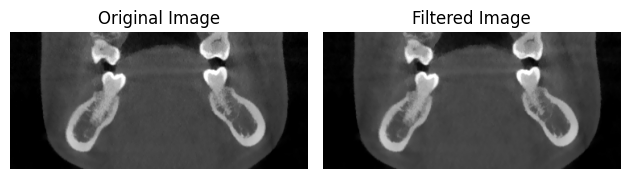

In [14]:
# plt.figure(figsize=(12, 5))

# Original image
plt.subplot(1, 2, 1)
plt.imshow(slice_2d, cmap='gray')
plt.title('Original Image')
plt.axis('off')

# Filtered image
plt.subplot(1, 2, 2)
plt.imshow(output, cmap='gray')
plt.title('Filtered Image')
plt.axis('off')

plt.tight_layout()
plt.show()

### Logarithmic transformation

In [15]:
def log_transform_for_denoising(image):
    """
    Apply logarithmic transformation to convert multiplicative to additive noise
    """
    epsilon = 1e-10
    original_min = np.min(image)
    if original_min <= 0:
        shifted_image = image - original_min + epsilon
    else:
        shifted_image = image + epsilon
        original_min = 0  # No shift needed

    log_image = np.log(shifted_image)
    return log_image, original_min, epsilon

def inverse_log_transform(log_image, original_min, epsilon):
    """
    Convert back from log domain to original intensity domain
    """
    reconstructed = np.exp(log_image)
    if original_min != 0:
        final_image = reconstructed + original_min - epsilon
    else:
        final_image = reconstructed - epsilon
    return final_image

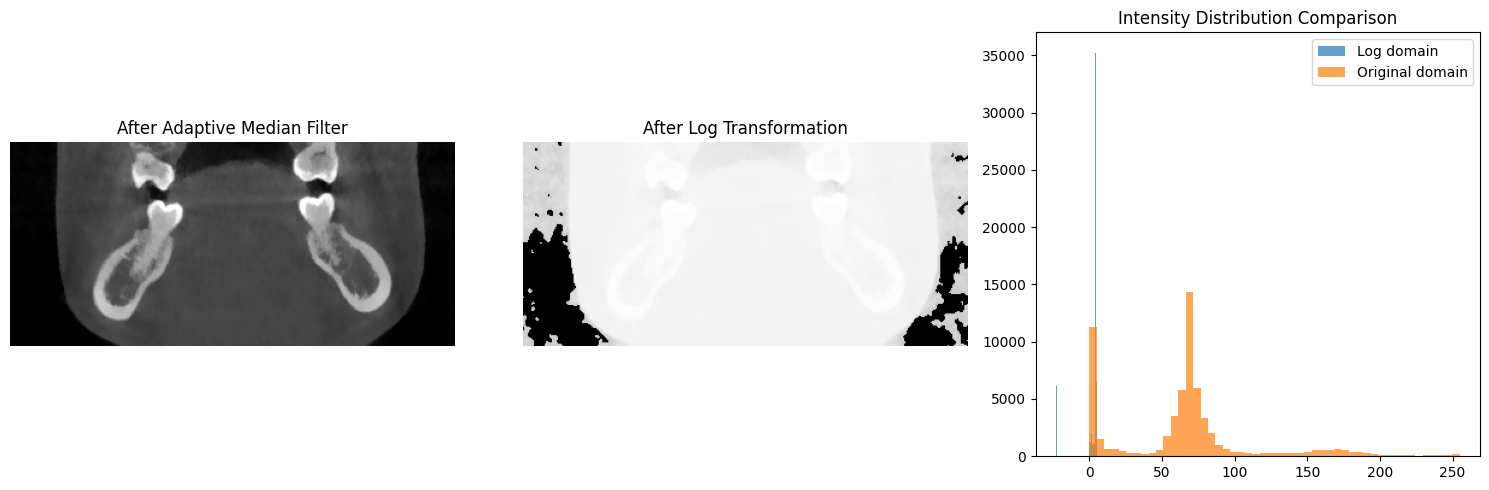

In [16]:
# Apply log transformation
log_transformed, original_min, eps = log_transform_for_denoising(output)

# Visualize the effect
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(output, cmap='gray')
plt.title('After Adaptive Median Filter')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(log_transformed, cmap='gray')
plt.title('After Log Transformation')
plt.axis('off')

# plt.subplot(1, 4, 3)
# plt.imshow(shifted_original, cmap='gray')
# plt.title('After Shifted original')
# plt.axis('off')

plt.subplot(1, 3, 3)
plt.hist(log_transformed.flatten(), bins=50, alpha=0.7, label='Log domain')
plt.hist(output.flatten(), bins=50, alpha=0.7, label='Original domain')
plt.title('Intensity Distribution Comparison')
plt.legend()

plt.tight_layout()
plt.show()

In [17]:
print(log_transformed)

[[ 1.00000008e-10  6.93147181e-01  6.93147181e-01 ...  2.07944154e+00
   2.19722458e+00  2.30258509e+00]
 [ 6.93147181e-01  6.93147181e-01  6.93147181e-01 ...  2.07944154e+00
   2.30258509e+00  2.30258509e+00]
 [ 6.93147181e-01  1.09861229e+00  1.09861229e+00 ...  2.07944154e+00
   2.19722458e+00  2.39789527e+00]
 ...
 [ 6.93147181e-01  6.93147181e-01  6.93147181e-01 ... -2.30258509e+01
  -2.30258509e+01 -2.30258509e+01]
 [ 1.00000008e-10  6.93147181e-01  6.93147181e-01 ... -2.30258509e+01
  -2.30258509e+01 -2.30258509e+01]
 [ 1.00000008e-10  1.00000008e-10  6.93147181e-01 ...  1.00000008e-10
   1.00000008e-10 -2.30258509e+01]]


### Wavelet transform ---> Adptive weiner filter, adaptive wavelet threshold ---> Inverse wavelet transform

In [18]:
import numpy as np
import pywt
from scipy.signal import wiener

def adaptive_wiener_filter(approx, noise_var, window_size=5):
    # Wiener filter expects 2D input; noise_var is the estimated noise variance
    return wiener(approx, mysize=window_size, noise=noise_var)

def adaptive_wavelet_threshold(detail, noise_sigma, threshold_factor=3):
    # Soft thresholding for adaptive wavelet thresholding
    T = threshold_factor * noise_sigma
    return np.sign(detail) * np.maximum(np.abs(detail) - T, 0)

def estimate_noise(detail_coeffs):
    # Median Absolute Deviation estimator for noise
    return np.median(np.abs(detail_coeffs)) / 0.6745

def denoise_log_transformed_image(log_image, wavelet='db4', level=2, window_size=5, threshold_factor=3):
    """
    Denoise a log-transformed image using adaptive Wiener filtering on the low-frequency
    coefficients and adaptive wavelet thresholding on high-frequency coefficients.
    Args:
        log_image: 2D numpy array, log-transformed image
        wavelet: Wavelet type (default 'db4')
        level: Number of decomposition levels
        window_size: Wiener filter window size
        threshold_factor: Scaling factor for threshold in wavelet thresholding
    Returns:
        2D numpy array: denoised image in log domain
    """
    # 1. Wavelet decomposition
    coeffs = pywt.wavedec2(log_image, wavelet=wavelet, level=level)
    cA, details = coeffs[0], coeffs[1:]

    # 2. Estimate noise from the finest scale diagonal detail coefficients (cD)
    noise_sigma = estimate_noise(details[-1][2])

    # 3. Apply Wiener filtering to low-frequency (approximation)
    cA_denoised = adaptive_wiener_filter(cA, noise_var=noise_sigma**2, window_size=window_size)

    # 4. Apply adaptive wavelet thresholding to high-frequency (details)
    details_denoised = []
    for (cH, cV, cD) in details:
        cH_denoised = adaptive_wavelet_threshold(cH, noise_sigma, threshold_factor)
        cV_denoised = adaptive_wavelet_threshold(cV, noise_sigma, threshold_factor)
        cD_denoised = adaptive_wavelet_threshold(cD, noise_sigma, threshold_factor)
        details_denoised.append((cH_denoised, cV_denoised, cD_denoised))

    # 5. Reconstruct the denoised image in the log domain
    coeffs_denoised = [cA_denoised] + details_denoised
    denoised_log_image = pywt.waverec2(coeffs_denoised, wavelet=wavelet)
    return denoised_log_image

# Example usage:
# log_image, original_min, epsilon = log_transform_for_denoising(image)
denoised_log = denoise_log_transformed_image(log_transformed)

### Inverse log transformed

In [19]:
inv_log=inverse_log_transform(denoised_log, original_min, eps)

(np.float64(-0.5), np.float64(369.5), np.float64(169.5), np.float64(-0.5))

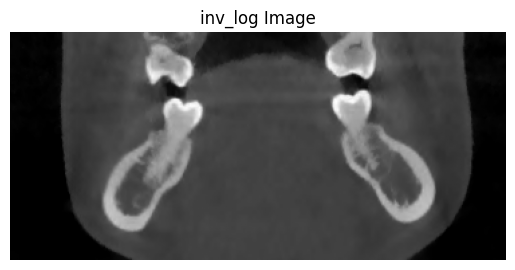

In [20]:
plt.imshow(inv_log, cmap='gray')
plt.title('inv_log Image')
plt.axis('off')

In [21]:
print(inv_log)

[[ 1.07849990e+00  1.92229421e+00  2.01269152e+00 ...  8.24049218e+00
   9.28860850e+00  9.98351543e+00]
 [ 2.00989831e+00  2.08808260e+00  2.08247895e+00 ...  8.37733861e+00
   9.74417437e+00  1.01822207e+01]
 [ 2.07093328e+00  2.92162671e+00  3.04103038e+00 ...  8.11517820e+00
   9.15169353e+00  1.09706115e+01]
 ...
 [ 2.02206735e+00  2.03769171e+00  2.02822489e+00 ...  1.27800857e-12
   3.57410080e-12  2.63718530e-12]
 [ 1.07996964e+00  1.88826171e+00  1.99652488e+00 ...  1.01661065e-11
   6.64549201e-13  4.05824794e-12]
 [ 1.01773325e+00  1.04958681e+00  2.00896246e+00 ...  1.03260537e+00
   9.73297430e-01 -3.68225142e-13]]


### Non-local mean filter

In [22]:
import numpy as np
from numba import jit

# Function to preprocess neighbors (small_window x small_window) for each pixel
@jit(nopython=True)
def findAllNeighbors(padImg, small_window, big_window, h, w):
    smallWidth = small_window // 2
    bigWidth = big_window // 2
    neighbors = np.zeros((padImg.shape[0], padImg.shape[1], small_window, small_window))
    for i in range(bigWidth, bigWidth + h):
        for j in range(bigWidth, bigWidth + w):
            neighbors[i, j] = padImg[(i - smallWidth):(i + smallWidth + 1), (j - smallWidth):(j + smallWidth + 1)]
    return neighbors

# Function to calculate the weighted average value (Ip) for each pixel
@jit(nopython=True)
def evaluateNorm(pixelWindow, neighborWindow, Nw):
    Ip_Numerator, Z = 0.0, 0.0
    for i in range(neighborWindow.shape[0]):
        for j in range(neighborWindow.shape[1]):
            q_window = neighborWindow[i, j]
            q_x, q_y = q_window.shape[0] // 2, q_window.shape[1] // 2
            Iq = q_window[q_x, q_y]
            w = np.exp(-1 * ((np.sum((pixelWindow - q_window) ** 2)) / Nw))
            Ip_Numerator += w * Iq
            Z += w
    return Ip_Numerator / Z if Z > 0 else 0.0

class NLMeansCustom:
    """
    Custom Non-Local Means implementation for grayscale images.
    """

    def apply(self, img, h=30, small_window=7, big_window=21):
        """
        Apply NLM filtering to a 2D grayscale image.
        :param img: 2D numpy array (grayscale image)
        :param h: filtering parameter (higher removes more noise)
        :param small_window: patch size
        :param big_window: search window size
        :return: denoised image (float64)
        """
        # Padding the original image with reflect mode
        padImg = np.pad(img, big_window // 2, mode='reflect')
        return self.NLM(padImg, img, h, small_window, big_window)

    @staticmethod
    @jit(nopython=True)
    def NLM(padImg, img, h, small_window, big_window):
        Nw = (h ** 2) * (small_window ** 2)
        h_img, w_img = img.shape
        result = np.zeros(img.shape)
        bigWidth = big_window // 2
        smallWidth = small_window // 2
        neighbors = findAllNeighbors(padImg, small_window, big_window, h_img, w_img)
        for i in range(bigWidth, bigWidth + h_img):
            for j in range(bigWidth, bigWidth + w_img):
                pixelWindow = neighbors[i, j]
                neighborWindow = neighbors[(i - bigWidth):(i + bigWidth + 1), (j - bigWidth):(j + bigWidth + 1)]
                Ip = evaluateNorm(pixelWindow, neighborWindow, Nw)
                result[i - bigWidth, j - bigWidth] = max(min(255, Ip), 0)
        return result

# Example usage in your flow:
# 1. Import and instantiate
# from nlmeans_custom import NLMeansCustom
nlm = NLMeansCustom()
#
# 2. Denoise your grayscale image (e.g., after log transform/inverse log, or on original)
denoised_img = nlm.apply(inv_log, h=5, small_window=5, big_window=25)
#
# 3. If you want uint8 output for visualization:
# denoised_img_uint8 = np.clip(denoised_img, 0, 255).astype(np.uint8)

(np.float64(-0.5), np.float64(369.5), np.float64(169.5), np.float64(-0.5))

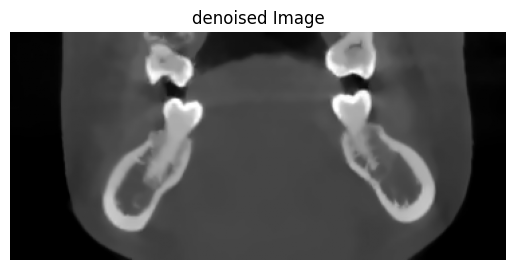

In [23]:
plt.imshow(denoised_img, cmap='gray')
plt.title('denoised Image')
plt.axis('off')

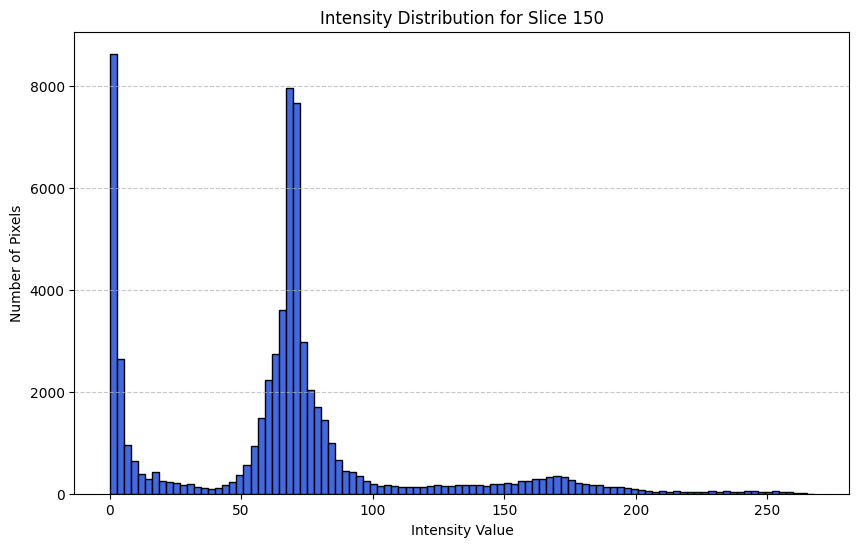

In [24]:
#visualise the slice contrast distribution
# Flatten the 2D slice into a 1D array
flattened_slice = inv_log.flatten()

# Plot the histogram of intensity values
plt.figure(figsize=(10, 6))
plt.hist(flattened_slice, bins=100, color='royalblue', edgecolor='black')
plt.title(f"Intensity Distribution for Slice {slice_index}")
plt.xlabel("Intensity Value")
plt.ylabel("Number of Pixels")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## Edge detection

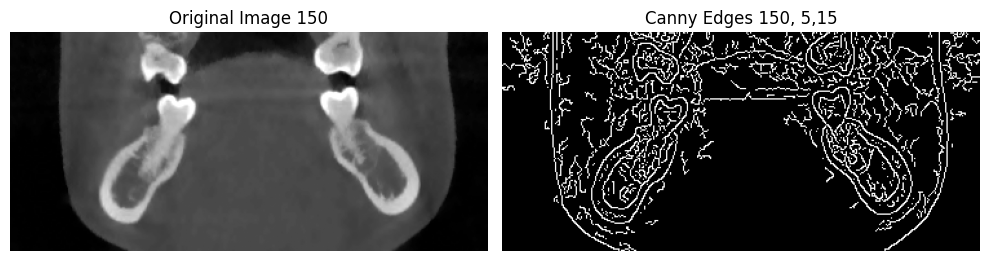

In [25]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def canny_edge_detection(image, low_threshold=100, high_threshold=200):
    """
    Applies Canny edge detection to an intensity image.

    Parameters:
        image (ndarray): Input image (already in intensity/uint8 scale).
        low_threshold (int): Lower bound for hysteresis thresholding.
        high_threshold (int): Upper bound for hysteresis thresholding.

    Returns:
        edges (ndarray): Binary image with detected edges.
    """
    # Ensure image is uint8 for OpenCV
    img_uint8 = np.clip(image, 0, 255).astype(np.uint8)
    edges = cv2.Canny(img_uint8, low_threshold, high_threshold)
    return edges

def apply_window(img, window_center, window_width):
    min_val = window_center - window_width // 2
    max_val = window_center + window_width // 2
    img_windowed = np.clip(img, min_val, max_val)
    img_norm = ((img_windowed - min_val) / (max_val - min_val) * 255).astype(np.uint8)
    return img_norm


# Example usage
if __name__ == "__main__":
    # Suppose 'denoised_img' is your input intensity image (replace with your actual variable)
    # denoised_img = ...

    # Example for soft tissue:
    denoised_img_uint8 = apply_window(inv_log, window_center=40, window_width=400)

    # # Convert if needed (uncomment if denoised_img is not already uint8)
    # denoised_img_uint8 = np.clip(inv_log, 0, 255).astype(np.uint8)
    lt=5
    ht=15

    edges = canny_edge_detection(denoised_img_uint8, low_threshold=lt, high_threshold=ht)

    plt.figure(figsize=(10,5))
    plt.subplot(1,2,1)
    plt.imshow(denoised_img_uint8, cmap='gray')
    plt.title(f'Original Image {slice_index}')
    plt.axis('off')

    plt.subplot(1,2,2)
    plt.imshow(edges, cmap='gray')
    plt.title(f'Canny Edges {slice_index}, {lt},{ht}')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

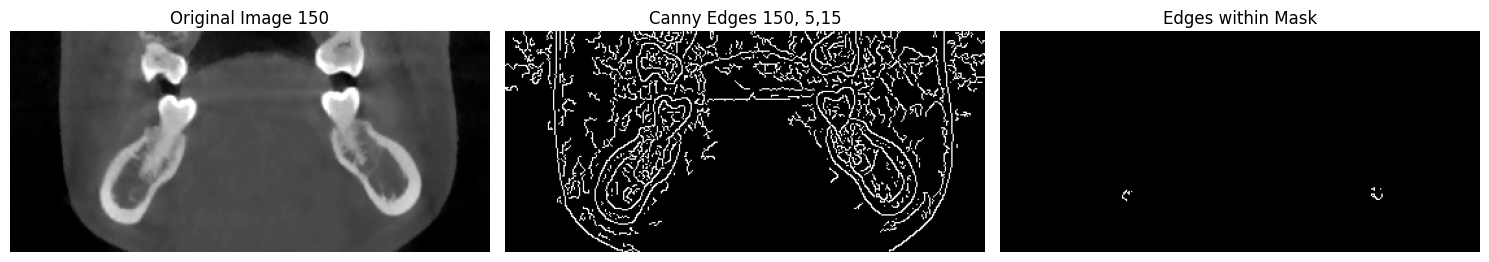

In [26]:
 # If your mask is boolean or uint8 (0 and 1), convert it to 0 and 255 for display if needed
mask_bin = (mask_2d > 0).astype(np.uint8)  # 1 inside mask, 0 outside

# Option 1: Element-wise multiplication
masked_edges = edges * mask_bin  # edges only where mask==1

# Option 2: Use OpenCV bitwise_and (if mask is 0 and 255)
masked_edges = cv2.bitwise_and(edges, edges, mask=mask_bin)

plt.figure(figsize=(15,5))
plt.subplot(1,3,1)
plt.imshow(denoised_img_uint8, cmap='gray')
plt.title(f'Original Image {slice_index}')
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(edges, cmap='gray')
plt.title(f'Canny Edges {slice_index}, {lt},{ht}')
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(masked_edges, cmap='gray')
plt.title('Edges within Mask')
plt.axis('off')

plt.tight_layout()
plt.show()

In [27]:
# # Extract edge points and compute intensity gradient
# gradient = np.gradient(denoised_img_uint8)
# magnitude = np.sqrt(gradient[0] ** 2 + gradient[1] ** 2)
# edge_points = np.column_stack(np.where(edges > 0))

In [28]:
# # Prepare point cloud data with mask labels
# point_cloud = []
# for point in edge_points:
#     x, y = point
#     grad = magnitude[x, y]
#     label = mask_2d[x, y]
#     point_cloud.append((y, x, grad, label))

In [29]:
# # Get the number of detected points
# num_points = len(edge_points)

# # Print the result
# print(f"Number of points detected: {num_points}")

In [30]:
# # Save point cloud data to .ply file
# with open("point_cloud_data_with_labels.ply", "w") as ply_file:
#     # Write the header
#     ply_file.write("ply\n")
#     ply_file.write("format ascii 1.0\n")
#     ply_file.write(f"element vertex {len(point_cloud)}\n")
#     ply_file.write("property float x\n")
#     ply_file.write("property float y\n")
#     ply_file.write("property float intensity_gradient\n")
#     ply_file.write("property uchar label\n")
#     ply_file.write("end_header\n")

#     # Write the point cloud data
#     for point in point_cloud:
#         ply_file.write(f"{point[0]} {point[1]} {point[2]} {point[3]}\n")

# print("Point cloud data saved to point_cloud_data_with_labels.ply")

In [31]:
# import numpy as np

# # Convert the point cloud list to a NumPy array
# point_cloud_array = np.array(point_cloud)

# # Save the point cloud as a .npy file
# np.save("/content/drive/MyDrive/Mphil/point_cloud.npy", point_cloud_array)

# print("Point cloud saved as 'point_cloud.npy'")

### Contour detection try

### Isolate only the white regions

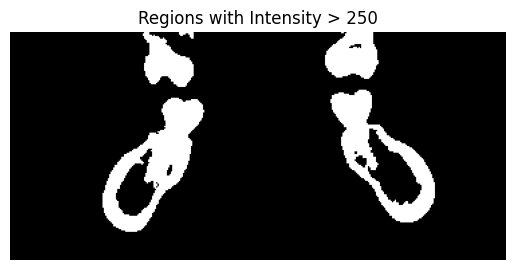

In [32]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# original_img: your grayscale image as a numpy array

# Threshold the image: keep pixels > 200
_, mask = cv2.threshold(denoised_img_uint8, 170, 255, cv2.THRESH_BINARY)

# mask is now a binary image (255 where original_img > 250, else 0)

# Visualize
plt.imshow(mask, cmap='gray')
plt.title('Regions with Intensity > 250')
plt.axis('off')
plt.show()

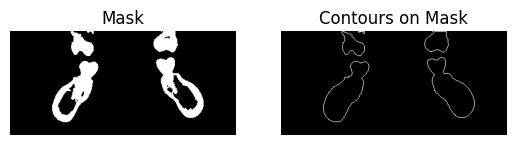

In [33]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# mask: your binary mask (0 and 255, or 0 and 1)

# Ensure mask is uint8 type and has values 0 and 255
mask_uint8 = (mask > 0).astype(np.uint8) * 255

# Find contours on the mask
contours, hierarchy = cv2.findContours(mask_uint8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Draw contours on a copy of the mask or a blank image
contour_img = np.zeros_like(mask_uint8)
cv2.drawContours(contour_img, contours, -1, 255, 1)  # thickness=2 for visibility

# Visualization
plt.subplot(1,2,1)
plt.imshow(mask_uint8, cmap='gray')
plt.title('Mask')
plt.axis('off')
plt.subplot(1,2,2)
plt.imshow(contour_img, cmap='gray')
plt.title('Contours on Mask')
plt.axis('off')
plt.show()

In [34]:
import cv2
import numpy as np

def contour_to_filled_mask(contour, shape, fill_value=1):
    """
    Fill the given contour and return the filled mask.

    Args:
        contour: A numpy array representing the contour (as returned by cv2.findContours).
        shape: Tuple (height, width) specifying the mask size.
        fill_value: Value to fill inside contour (default 1).

    Returns:
        mask: np.uint8 mask with filled contour (fill_value inside, 0 outside).
    """
    mask = np.zeros(shape, dtype=np.uint8)
    cv2.drawContours(mask, contour, -1, fill_value, thickness=-1)
    return mask

# Example usage:
shape = mask_uint8.shape[:2]
mask = contour_to_filled_mask(contours, shape)

(np.float64(-0.5), np.float64(369.5), np.float64(169.5), np.float64(-0.5))

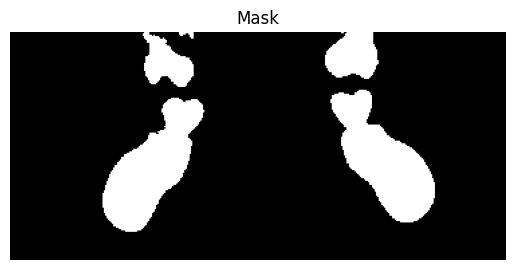

In [35]:
plt.imshow(mask, cmap='gray')
plt.title('Mask')
plt.axis('off')

In [36]:
print(mask)

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


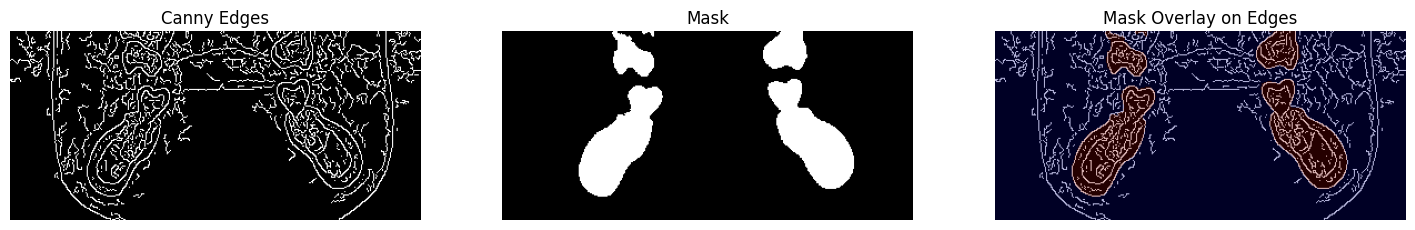

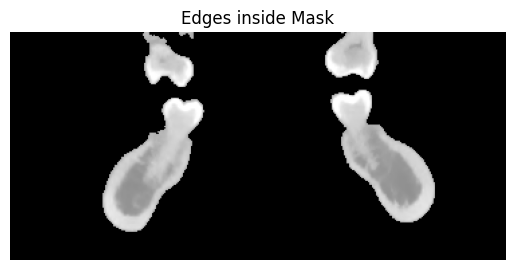

In [37]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Assuming:
# edges: your Canny edge image (uint8, 0/255)
# mask: your binary mask (0 and 255, or 0 and 1)

# 1. Ensure mask is 0 and 1
mask_bool = (mask > 0).astype(np.uint8)

# # 2. Filter out only the masked area from the edges
# # edges_masked = edges * mask_bool
# edges_masked = denoised_img_uint8 * mask_bool

# If your mask is 0/1, scale it to 0/255 for OpenCV compatibility
# mask_cv = (mask_bool).astype(np.uint8)

# For grayscale image:
masked_img = cv2.bitwise_and(denoised_img_uint8, denoised_img_uint8, mask=mask_bool)


# 3. Plot results
plt.figure(figsize=(18,6))
plt.subplot(1,3,1)
plt.imshow(edges, cmap='gray')
plt.title('Canny Edges')
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(mask, cmap='gray')
plt.title('Mask')
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(edges, cmap='gray')
plt.imshow(mask, cmap='jet', alpha=0.3)  # Overlay mask with transparency
plt.title('Mask Overlay on Edges')
plt.axis('off')

plt.show()

# If you want to display ONLY the filtered edges:
plt.figure()
plt.imshow(masked_img, cmap='gray')
plt.title('Edges inside Mask')
plt.axis('off')
plt.show()

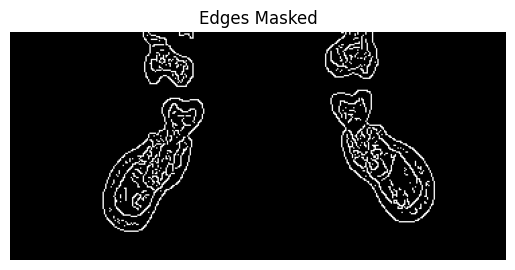

In [38]:
edges_masked = canny_edge_detection(masked_img, low_threshold=lt, high_threshold=ht)

plt.figure()
plt.imshow(edges_masked, cmap='gray')
plt.title('Edges Masked')
plt.axis('off')
plt.show()

In [39]:
print(mask_bool)

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


### Pointcloud formulation

In [40]:
# Extract edge points and compute intensity gradient
gradient = np.gradient(masked_img)
magnitude = np.sqrt(gradient[0] ** 2 + gradient[1] ** 2)
edge_points = np.column_stack(np.where(edges_masked > 0))

In [41]:
# Prepare point cloud data with mask labels
point_cloud = []
for point in edge_points:
    x, y = point
    grad = magnitude[x, y]
    label = mask_2d[x, y]
    point_cloud.append((y, x, grad, label))

In [42]:
# Get the number of detected points
num_points = len(edge_points)

# Print the result
print(f"Number of points detected: {num_points}")

Number of points detected: 2530


In [43]:
# Save point cloud data to .ply file
with open("point_cloud_data_with_labels.ply", "w") as ply_file:
    # Write the header
    ply_file.write("ply\n")
    ply_file.write("format ascii 1.0\n")
    ply_file.write(f"element vertex {len(point_cloud)}\n")
    ply_file.write("property float x\n")
    ply_file.write("property float y\n")
    ply_file.write("property float intensity_gradient\n")
    ply_file.write("property uchar label\n")
    ply_file.write("end_header\n")

    # Write the point cloud data
    for point in point_cloud:
        ply_file.write(f"{point[0]} {point[1]} {point[2]} {point[3]}\n")

print("Point cloud data saved to point_cloud_data_with_labels.ply")

Point cloud data saved to point_cloud_data_with_labels.ply


In [44]:
import numpy as np

# Convert the point cloud list to a NumPy array
point_cloud_array = np.array(point_cloud)

# Save the point cloud as a .npy file
np.save("/content/drive/MyDrive/Mphil/point_cloud.npy", point_cloud_array)

print("Point cloud saved as 'point_cloud.npy'")

Point cloud saved as 'point_cloud.npy'


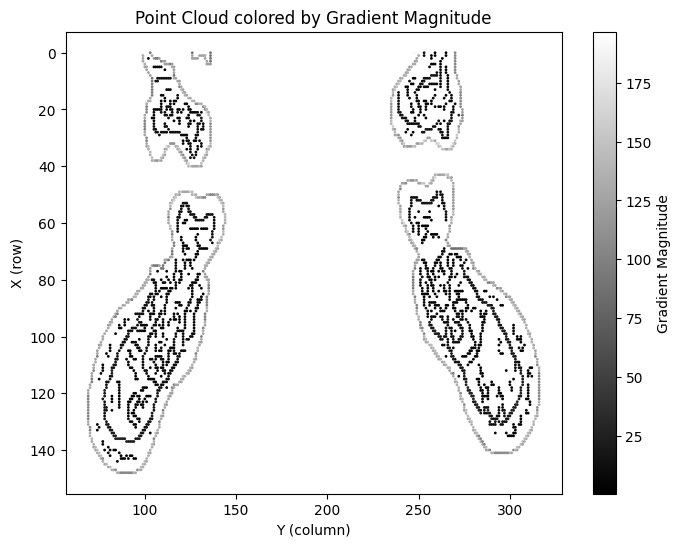

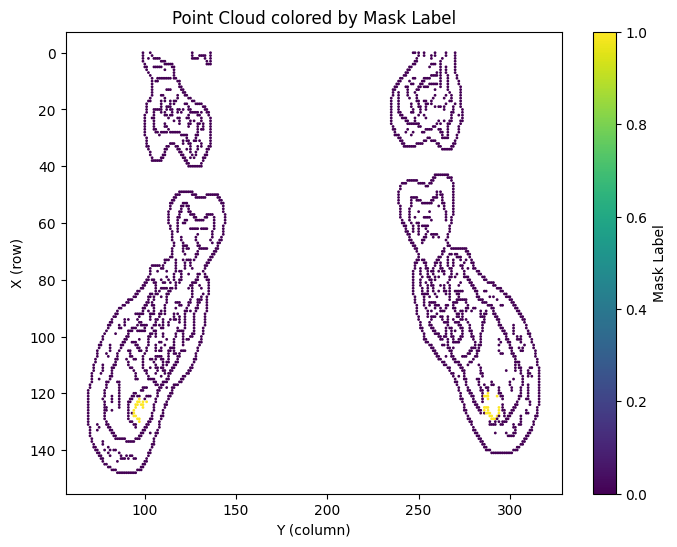

In [45]:
import numpy as np
import matplotlib.pyplot as plt

# Load your point cloud
points = np.load('/content/drive/MyDrive/Mphil/point_cloud.npy')

# Unpack columns for clarity
y, x, grad, label = points[:,0], points[:,1], points[:,2], points[:,3]

# Plot x vs y, colored by grad
plt.figure(figsize=(8,6))
sc = plt.scatter(y, x, c=grad, cmap='gray', s=1)
plt.colorbar(sc, label='Gradient Magnitude')
plt.xlabel('Y (column)')
plt.ylabel('X (row)')
plt.title('Point Cloud colored by Gradient Magnitude')
plt.gca().invert_yaxis()
plt.show()

# Plot x vs y, colored by label
plt.figure(figsize=(8,6))
sc = plt.scatter(y, x, c=label, cmap='viridis', s=1)  # tab10 works well for integer labels
plt.colorbar(sc, label='Mask Label')
plt.xlabel('Y (column)')
plt.ylabel('X (row)')
plt.title('Point Cloud colored by Mask Label')
plt.gca().invert_yaxis()
plt.show()

In [46]:
print(points)

[[ 99.           0.         196.65006992   0.        ]
 [103.           0.          95.92314632   0.        ]
 [126.           0.          92.19544457   0.        ]
 ...
 [ 93.         148.         103.54346913   0.        ]
 [ 94.         148.         136.55859548   0.        ]
 [ 95.         148.         131.71180661   0.        ]]
